# AI Resume Screening Dataset Analysis

## Introduction

The AI Resume Screening project focuses on analyzing candidate information to understand the factors associated with recruitment selection. The dataset contains candidate profiles, educational qualifications, work experience, technical skills, assessment scores, and resume-related information.

The project involves data cleaning, exploratory data analysis (EDA), statistical analysis, feature preparation, and machine learning to predict whether a candidate is **Selected** or **Rejected**.

## Project Objectives

- Understand the structure and characteristics of the dataset.
- Identify and remove unnecessary columns.
- Check for missing values and data quality issues.
- Explore numerical and categorical features using statistical methods and visualizations.
- Analyze relationships between candidate features and selection status.
- Prepare the data for machine learning.
- Build and evaluate a model to predict candidate selection.

##  Dataset Overview

The dataset is loaded using the Pandas library. Its structure, dimensions, column names, and data types are examined to understand the available information before performing data cleaning and analysis.

In [17]:
# Import libraries required for data analysis and visualization

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Import libraries required for machine learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)

print("All required libraries imported successfully!")

All required libraries imported successfully!


In [18]:
import pandas as pd

df = pd.read_csv("ai_resume_screening_dataset.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [19]:
df.head()

,candidate_id,full_name,email,phone,country,city,age,gender,highest_education,university,...,expected_salary,preferred_location,employment_type,remote_preference,availability,resume_quality_score,resume_length,keyword_match_percentage,ats_score,selected
0,CAND-000001,Allison Hill,allison.hill13@gmail.com,+1-959-381-5012,Burundi,Lake Joyside,35,Female,Master,Georgia Institute of Technology,...,172000,Burundi,Internship,Hybrid,30 Days,72,2,20.00,46,Selected
1,CAND-000002,Javier Johnson,javier.johnson58@gmail.com,+1-299-467-6635,Djibouti,New Jamesside,37,Male,Master,National University of Singapore,...,212000,Djibouti,Contract,Remote,Immediate,77,2,20.68,46,Rejected
2,CAND-000003,Jerry Ramirez,jerry.ramirez58@gmail.com,+1-476-755-4598,Senegal,Lake Roberto,41,Male,Bachelor,Massachusetts Institute of Technology,...,193000,Flexible,Full-Time,On-site,Immediate,58,2,62.55,65,Selected
3,CAND-000004,Daniel Gallagher,daniel.gallagher18@gmail.com,+1-594-490-8668,Bermuda,Davisstad,54,Male,PhD,Imperial College London,...,351000,Davisstad,Contract,Hybrid,Immediate,61,1,28.58,43,Selected
4,CAND-000005,Robert Blair,robert.blair40@hotmail.com,+1-780-180-2403,British Virgin Islands,Millerport,52,Male,PhD,National University of Singapore,...,374000,Millerport,Part-Time,Remote,15 Days,62,1,20.00,46,Selected


In [20]:
display(df.tail())

,candidate_id,full_name,email,phone,country,city,age,gender,highest_education,university,...,expected_salary,preferred_location,employment_type,remote_preference,availability,resume_quality_score,resume_length,keyword_match_percentage,ats_score,selected
99995,CAND-099996,Andrew Arias,andrew.arias24@gmail.com,+1-784-562-6739,Colombia,Port Kenneth,42,Male,Master,Harvard University,...,228000,Port Kenneth,Contract,Hybrid,Immediate,67,1,23.44,40,Rejected
99996,CAND-099997,John Ferrell,john.ferrell96@yahoo.com,+1-359-920-6427,Saint Vincent and the Grenadines,Stevenfort,35,Male,Bachelor,Massachusetts Institute of Technology,...,132000,Stevenfort,Contract,Hybrid,30 Days,80,4,24.39,57,Selected
99997,CAND-099998,Andrew Martin,andrew.martin22@gmail.com,+1-566-875-4585,Saint Kitts and Nevis,New Melissa,53,Male,Master,Carnegie Mellon University,...,299000,International,Part-Time,Remote,90 Days,72,2,20.00,49,Rejected
99998,CAND-099999,Jacob Avila,jacob.avila54@gmail.com,+1-508-963-2447,Wallis and Futuna,Amberport,52,Male,Bachelor,Carnegie Mellon University,...,253000,Flexible,Full-Time,Hybrid,30 Days,75,2,26.54,46,Selected
99999,CAND-100000,Brent Smith,brent.smith13@hotmail.com,+1-698-327-2581,India,West Jennifer,21,Male,High School,"University of California, Berkeley",...,81000,International,Full-Time,On-site,15 Days,82,1,24.77,50,Rejected


In [21]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 100000
Number of columns: 44


In [22]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 44 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   candidate_id              100000 non-null  str    
 1   full_name                 100000 non-null  str    
 2   email                     100000 non-null  str    
 3   phone                     100000 non-null  str    
 4   country                   100000 non-null  str    
 5   city                      100000 non-null  str    
 6   age                       100000 non-null  int64  
 7   gender                    100000 non-null  str    
 8   highest_education         100000 non-null  str    
 9   university                100000 non-null  str    
 10  field_of_study            100000 non-null  str    
 11  cgpa                      100000 non-null  float64
 12  graduation_year           100000 non-null  int64  
 13  experience_years          100000 non-null  int64  
 14  

##  Data Cleaning

Data cleaning is performed to check the quality and structure of the dataset before analysis. This stage includes identifying missing values, reviewing unnecessary columns, and preparing the relevant candidate information for further analysis and machine learning.

In [23]:
df.isnull().sum()

candidate_id                0
full_name                   0
email                       0
phone                       0
country                     0
city                        0
age                         0
gender                      0
highest_education           0
university                  0
field_of_study              0
cgpa                        0
graduation_year             0
experience_years            0
previous_companies          0
current_job_title           0
internship_experience       0
leadership_experience       0
technical_skills            0
programming_languages       0
frameworks                  0
databases                   0
cloud_platform              0
projects_completed          0
github_profile              0
linkedin_profile            0
certifications              0
publications                0
communication_score         0
problem_solving_score       0
technical_test_score        0
interview_score             0
aptitude_score              0
job_role  

In [24]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [25]:
(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 44 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   candidate_id              100000 non-null  str    
 1   full_name                 100000 non-null  str    
 2   email                     100000 non-null  str    
 3   phone                     100000 non-null  str    
 4   country                   100000 non-null  str    
 5   city                      100000 non-null  str    
 6   age                       100000 non-null  int64  
 7   gender                    100000 non-null  str    
 8   highest_education         100000 non-null  str    
 9   university                100000 non-null  str    
 10  field_of_study            100000 non-null  str    
 11  cgpa                      100000 non-null  float64
 12  graduation_year           100000 non-null  int64  
 13  experience_years          100000 non-null  int64  
 14  

###  Missing Value Analysis

Missing values are checked to identify incomplete records in the dataset. This helps determine whether any missing-data treatment is required before further analysis.

In [26]:
df.isnull().sum()

candidate_id                0
full_name                   0
email                       0
phone                       0
country                     0
city                        0
age                         0
gender                      0
highest_education           0
university                  0
field_of_study              0
cgpa                        0
graduation_year             0
experience_years            0
previous_companies          0
current_job_title           0
internship_experience       0
leadership_experience       0
technical_skills            0
programming_languages       0
frameworks                  0
databases                   0
cloud_platform              0
projects_completed          0
github_profile              0
linkedin_profile            0
certifications              0
publications                0
communication_score         0
problem_solving_score       0
technical_test_score        0
interview_score             0
aptitude_score              0
job_role  

###  Removing Unnecessary Columns



The original dataset is preserved, and a separate cleaned dataset is created by removing identifying information and profile links that will not be used as direct model inputs. This approach retains the original data for reference while preparing a suitable dataset for further analysis.

In [27]:
# Keep the original dataset unchanged
df_original = pd.read_csv("ai_resume_screening_dataset.csv")


# Create a copy for cleaning
df_cleaned = df_original.copy()

# Columns to remove
cols_to_drop = [
    'candidate_id',
    'full_name',
    'email',
    'phone',
    'github_profile',
    'linkedin_profile'
]

# Remove only columns that exist
existing_cols = [
    col for col in cols_to_drop
    if col in df_cleaned.columns
]

df_cleaned = df_cleaned.drop(columns=existing_cols)

print("Original shape:", df_original.shape)
print("Cleaned shape:", df_cleaned.shape)
print("Removed columns:", existing_cols)

Original shape: (100000, 44)
Cleaned shape: (100000, 38)
Removed columns: ['candidate_id', 'full_name', 'email', 'phone', 'github_profile', 'linkedin_profile']


In [28]:
df.head()

,candidate_id,full_name,email,phone,country,city,age,gender,highest_education,university,...,expected_salary,preferred_location,employment_type,remote_preference,availability,resume_quality_score,resume_length,keyword_match_percentage,ats_score,selected
0,CAND-000001,Allison Hill,allison.hill13@gmail.com,+1-959-381-5012,Burundi,Lake Joyside,35,Female,Master,Georgia Institute of Technology,...,172000,Burundi,Internship,Hybrid,30 Days,72,2,20.00,46,Selected
1,CAND-000002,Javier Johnson,javier.johnson58@gmail.com,+1-299-467-6635,Djibouti,New Jamesside,37,Male,Master,National University of Singapore,...,212000,Djibouti,Contract,Remote,Immediate,77,2,20.68,46,Rejected
2,CAND-000003,Jerry Ramirez,jerry.ramirez58@gmail.com,+1-476-755-4598,Senegal,Lake Roberto,41,Male,Bachelor,Massachusetts Institute of Technology,...,193000,Flexible,Full-Time,On-site,Immediate,58,2,62.55,65,Selected
3,CAND-000004,Daniel Gallagher,daniel.gallagher18@gmail.com,+1-594-490-8668,Bermuda,Davisstad,54,Male,PhD,Imperial College London,...,351000,Davisstad,Contract,Hybrid,Immediate,61,1,28.58,43,Selected
4,CAND-000005,Robert Blair,robert.blair40@hotmail.com,+1-780-180-2403,British Virgin Islands,Millerport,52,Male,PhD,National University of Singapore,...,374000,Millerport,Part-Time,Remote,15 Days,62,1,20.00,46,Selected


###  Verification of the Cleaned Dataset

After removing unnecessary identifying columns, the cleaned dataset is inspected to confirm that the operation was successful. The dataset's dimensions, column information, and sample records are examined before proceeding to exploratory data analysis.

In [29]:
print("Original dataset shape:", df_original.shape)
print("Cleaned dataset shape:", df_cleaned.shape)
print("Remaining columns:", df_cleaned.columns.tolist())

Original dataset shape: (100000, 44)
Cleaned dataset shape: (100000, 38)
Remaining columns: ['country', 'city', 'age', 'gender', 'highest_education', 'university', 'field_of_study', 'cgpa', 'graduation_year', 'experience_years', 'previous_companies', 'current_job_title', 'internship_experience', 'leadership_experience', 'technical_skills', 'programming_languages', 'frameworks', 'databases', 'cloud_platform', 'projects_completed', 'certifications', 'publications', 'communication_score', 'problem_solving_score', 'technical_test_score', 'interview_score', 'aptitude_score', 'job_role', 'expected_salary', 'preferred_location', 'employment_type', 'remote_preference', 'availability', 'resume_quality_score', 'resume_length', 'keyword_match_percentage', 'ats_score', 'selected']


In [30]:
df_cleaned.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 38 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   country                   100000 non-null  str    
 1   city                      100000 non-null  str    
 2   age                       100000 non-null  int64  
 3   gender                    100000 non-null  str    
 4   highest_education         100000 non-null  str    
 5   university                100000 non-null  str    
 6   field_of_study            100000 non-null  str    
 7   cgpa                      100000 non-null  float64
 8   graduation_year           100000 non-null  int64  
 9   experience_years          100000 non-null  int64  
 10  previous_companies        100000 non-null  str    
 11  current_job_title         100000 non-null  str    
 12  internship_experience     100000 non-null  str    
 13  leadership_experience     100000 non-null  str    
 14  

In [31]:
df_cleaned.head()

,country,city,age,gender,highest_education,university,field_of_study,cgpa,graduation_year,experience_years,...,expected_salary,preferred_location,employment_type,remote_preference,availability,resume_quality_score,resume_length,keyword_match_percentage,ats_score,selected
0,Burundi,Lake Joyside,35,Female,Master,Georgia Institute of Technology,Mathematics & Statistics,2.63,2011,14,...,172000,Burundi,Internship,Hybrid,30 Days,72,2,20.00,46,Selected
1,Djibouti,New Jamesside,37,Male,Master,National University of Singapore,Software Engineering,3.96,2008,17,...,212000,Djibouti,Contract,Remote,Immediate,77,2,20.68,46,Rejected
2,Senegal,Lake Roberto,41,Male,Bachelor,Massachusetts Institute of Technology,Artificial Intelligence,3.10,2005,21,...,193000,Flexible,Full-Time,On-site,Immediate,58,2,62.55,65,Selected
3,Bermuda,Davisstad,54,Male,PhD,Imperial College London,Computer Science,3.52,1994,32,...,351000,Davisstad,Contract,Hybrid,Immediate,61,1,28.58,43,Selected
4,British Virgin Islands,Millerport,52,Male,PhD,National University of Singapore,Data Science,2.69,1993,32,...,374000,Millerport,Part-Time,Remote,15 Days,62,1,20.00,46,Selected


#  Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand the characteristics, distributions, and relationships within the AI Resume Screening dataset. Statistical calculations, numerical analysis, and graphical visualizations are used to identify patterns in candidate qualifications, assessment scores, resume quality, and selection outcomes.

In [32]:
# Calculate count, mean, standard deviation, quartiles, minimum and maximum
print(df_cleaned.describe())

                 age           cgpa  graduation_year  experience_years  \
count  100000.000000  100000.000000    100000.000000     100000.000000   
mean       37.992810       3.248341      2008.946510         16.055770   
std        10.095701       0.433409        10.134017         10.101397   
min        21.000000       2.500000      1989.000000          0.000000   
25%        29.000000       2.870000      2000.000000          7.000000   
50%        38.000000       3.250000      2009.000000         16.000000   
75%        47.000000       3.620000      2018.000000         25.000000   
max        55.000000       4.000000      2026.000000         35.000000   

       projects_completed   publications  communication_score  \
count        100000.00000  100000.000000        100000.000000   
mean              6.49118       0.379640            69.434840   
std               3.45233       0.744781            14.655934   
min               1.00000       0.000000            30.000000   
25%     

In [33]:
# Calculate mean, median and mode of candidate age
print("Mean:", df_cleaned['age'].mean())
print("Median:", df_cleaned['age'].median())
print("Mode:", df_cleaned['age'].mode().tolist())

Mean: 37.99281
Median: 38.0
Mode: [35]


In [34]:
# Calculate variance and standard deviation of work experience
print("Variance:", df_cleaned['experience_years'].var())
print("Standard Deviation:", df_cleaned['experience_years'].std())

Variance: 102.03822008930089
Standard Deviation: 10.101396937518142


In [35]:
# Find minimum, maximum and range of candidate CGPA
print("Minimum CGPA:", df_cleaned['cgpa'].min())
print("Maximum CGPA:", df_cleaned['cgpa'].max())
print("CGPA Range:", df_cleaned['cgpa'].max() - df_cleaned['cgpa'].min())

Minimum CGPA: 2.5
Maximum CGPA: 4.0
CGPA Range: 1.5


In [36]:
# Calculate the 25th, 50th and 75th percentiles of technical test scores
print(df_cleaned['technical_test_score'].quantile([0.25, 0.50, 0.75]))

0.25    57.0
0.50    67.0
0.75    78.0
Name: technical_test_score, dtype: float64


In [37]:
# Display the number of selected and rejected candidates
print(df_cleaned['selected'].value_counts())

selected
Selected    50000
Rejected    50000
Name: count, dtype: int64


In [38]:
# Display the percentage distribution of selection outcomes
print((df_cleaned['selected'].value_counts(normalize=True) * 100).round(2))

selected
Selected    50.0
Rejected    50.0
Name: proportion, dtype: float64


In [39]:
# Count candidates in each education category
print(df_cleaned['highest_education'].value_counts())

highest_education
Bachelor       54807
Master         25285
Diploma        10018
High School     5001
PhD             4889
Name: count, dtype: int64


In [40]:
# Display candidate counts for each job role
print(df_cleaned['job_role'].value_counts())

job_role
Frontend Developer           6859
Machine Learning Engineer    6751
Business Analyst             6709
Data Scientist               6692
AI Engineer                  6687
Mobile App Developer         6683
Cloud Engineer               6681
DevOps Engineer              6681
Full Stack Developer         6658
Cyber Security Analyst       6657
UI UX Designer               6638
Database Administrator       6621
Software Engineer            6599
Backend Developer            6591
QA Engineer                  6493
Name: count, dtype: int64


In [41]:
# Count candidates by internship experience category
print(df_cleaned['internship_experience'].value_counts())

internship_experience
No     55179
Yes    44821
Name: count, dtype: int64


In [42]:
# Display the distribution of employment types
print(df_cleaned['employment_type'].value_counts())

employment_type
Full-Time     25070
Part-Time     25048
Contract      24970
Internship    24912
Name: count, dtype: int64


In [43]:
# Count candidates by remote work preference
print(df_cleaned['remote_preference'].value_counts())

remote_preference
On-site    33366
Hybrid     33350
Remote     33284
Name: count, dtype: int64

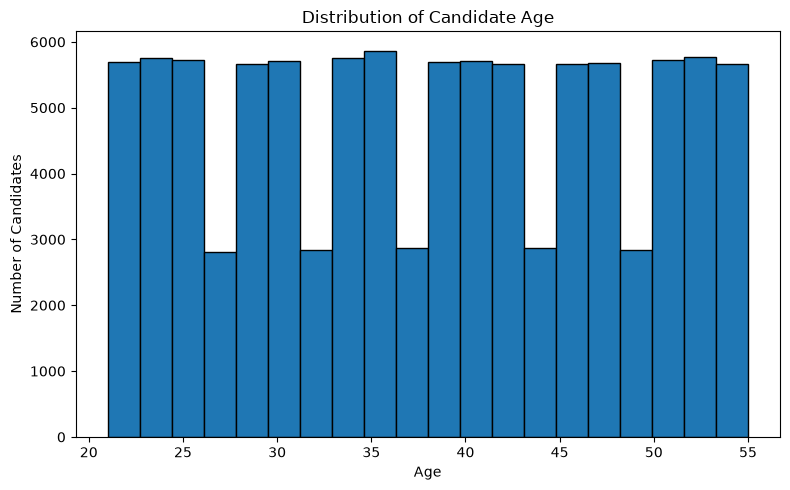

In [44]:
# Plot a histogram of candidate age
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(df_cleaned['age'].dropna(), bins=20, edgecolor='black')
plt.title('Distribution of Candidate Age')
plt.xlabel('Age')
plt.ylabel('Number of Candidates')
plt.tight_layout()
plt.show()

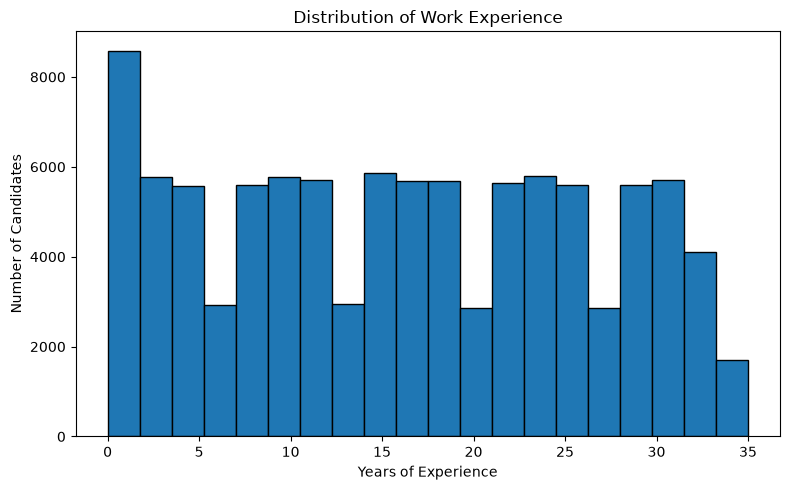

In [45]:
# Plot a histogram of years of work experience
plt.figure(figsize=(8, 5))
plt.hist(df_cleaned['experience_years'].dropna(), bins=20, edgecolor='black')
plt.title('Distribution of Work Experience')
plt.xlabel('Years of Experience')
plt.ylabel('Number of Candidates')
plt.tight_layout()
plt.show()

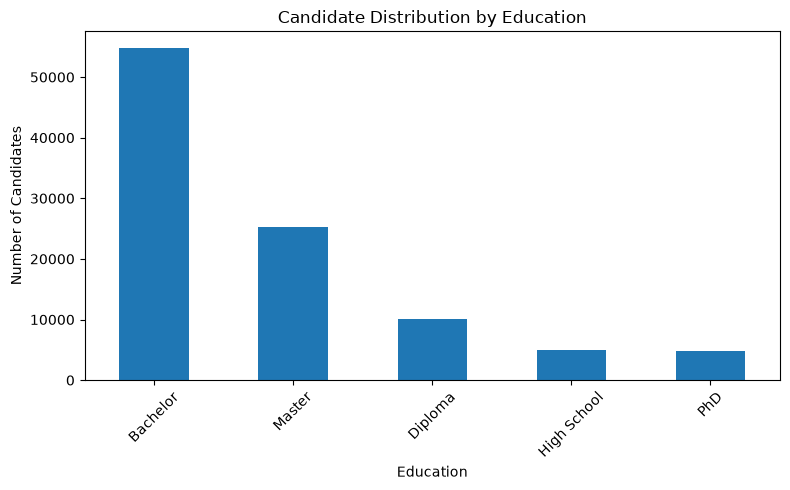

In [46]:
# Compare the number of candidates in each education category
df_cleaned['highest_education'].value_counts().plot(
    kind='bar', figsize=(8, 5), rot=45
)
plt.title('Candidate Distribution by Education')
plt.xlabel('Education')
plt.ylabel('Number of Candidates')
plt.tight_layout()
plt.show()

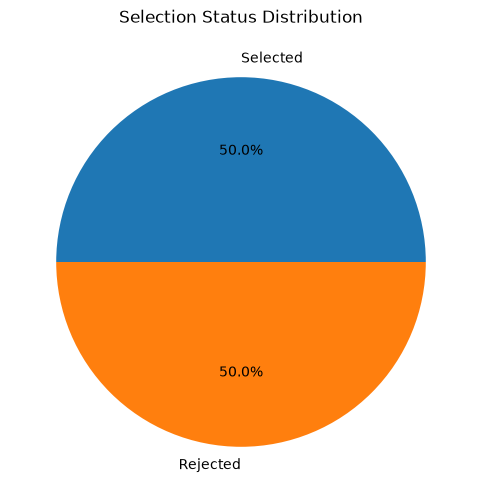

In [47]:
# Display selected and rejected candidates as a pie chart
df_cleaned['selected'].value_counts().plot(
    kind='pie', autopct='%1.1f%%', figsize=(6, 6)
)
plt.title('Selection Status Distribution')
plt.ylabel('')
plt.show()

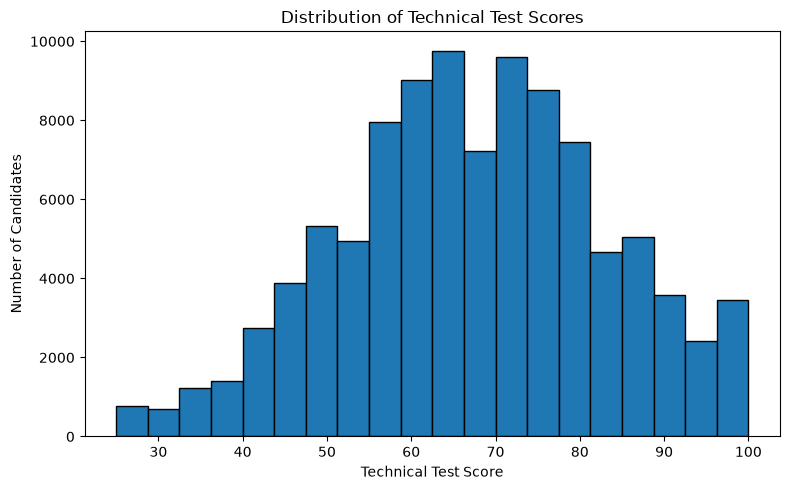

In [48]:
# Plot the distribution of technical test scores
plt.figure(figsize=(8, 5))
plt.hist(df_cleaned['technical_test_score'].dropna(), bins=20, edgecolor='black')
plt.title('Distribution of Technical Test Scores')
plt.xlabel('Technical Test Score')
plt.ylabel('Number of Candidates')
plt.tight_layout()
plt.show()

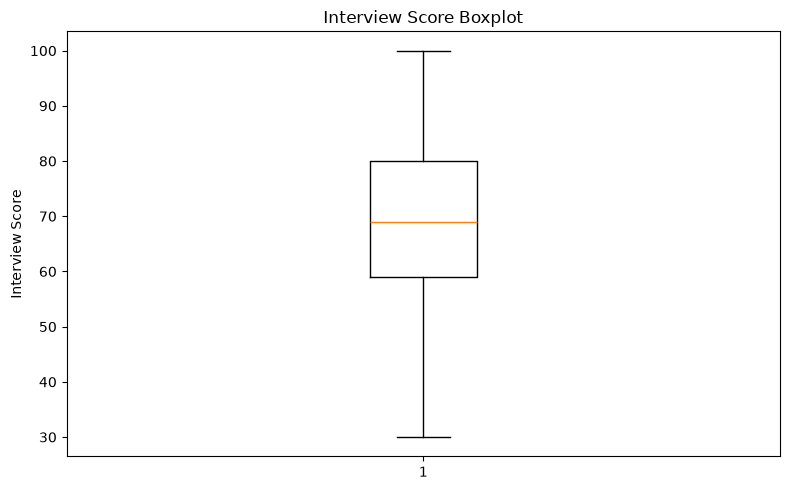

In [49]:
# Use a boxplot to examine the spread and potential outliers in interview scores
plt.figure(figsize=(8, 5))
plt.boxplot(df_cleaned['interview_score'].dropna())
plt.title('Interview Score Boxplot')
plt.ylabel('Interview Score')
plt.tight_layout()
plt.show()

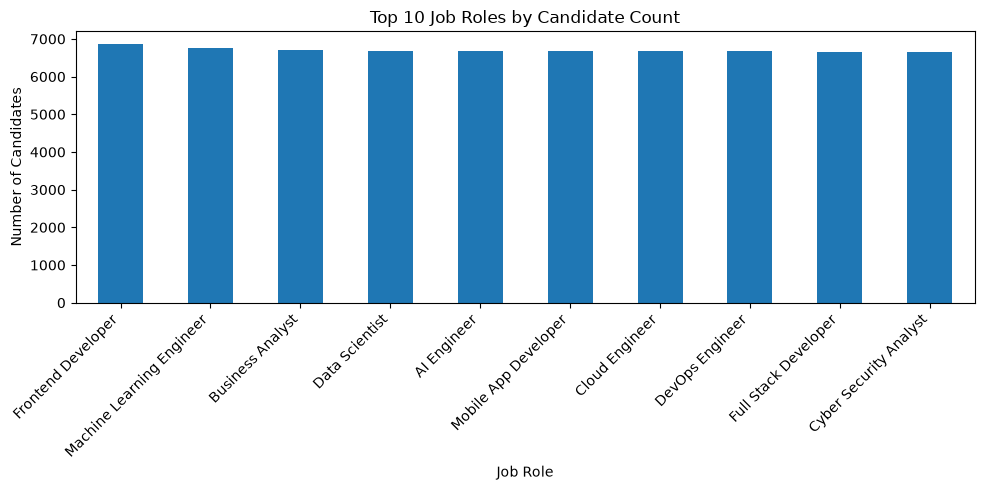

In [50]:
# Plot the ten job roles with the highest candidate counts
df_cleaned['job_role'].value_counts().head(10).plot(
    kind='bar', figsize=(10, 5)
)
plt.title('Top 10 Job Roles by Candidate Count')
plt.xlabel('Job Role')
plt.ylabel('Number of Candidates')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

selected
Rejected    10.30646
Selected    21.80508
Name: experience_years, dtype: float64


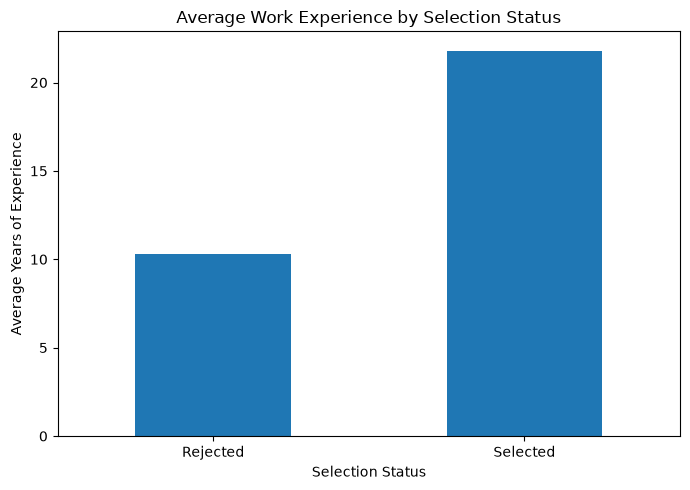

In [51]:
# Calculate and visualize average work experience for selected and rejected candidates
experience_by_selection = df_cleaned.groupby('selected')['experience_years'].mean()

print(experience_by_selection)

experience_by_selection.plot(kind='bar', rot=0, figsize=(7, 5))
plt.title('Average Work Experience by Selection Status')
plt.xlabel('Selection Status')
plt.ylabel('Average Years of Experience')
plt.tight_layout()
plt.show()

selected
Rejected    3.189266
Selected    3.307416
Name: cgpa, dtype: float64


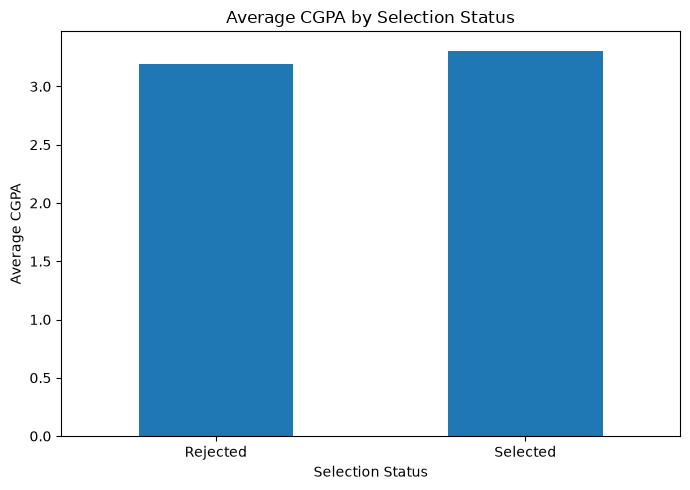

In [52]:
# Calculate and compare average CGPA across selection categories
cgpa_by_selection = df_cleaned.groupby('selected')['cgpa'].mean()

print(cgpa_by_selection)

cgpa_by_selection.plot(kind='bar', rot=0, figsize=(7, 5))
plt.title('Average CGPA by Selection Status')
plt.xlabel('Selection Status')
plt.ylabel('Average CGPA')
plt.tight_layout()
plt.show()

selected
Rejected    64.61420
Selected    70.04386
Name: technical_test_score, dtype: float64


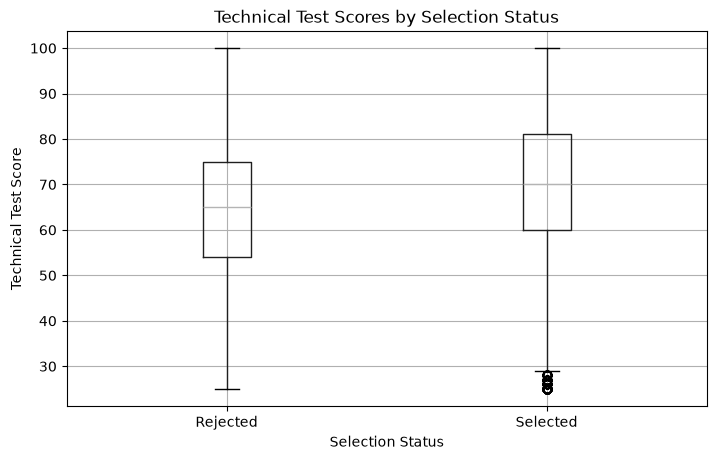

In [53]:
# Compare technical test score distributions using a boxplot
print(df_cleaned.groupby('selected')['technical_test_score'].mean())

df_cleaned.boxplot(column='technical_test_score', by='selected', figsize=(8, 5))
plt.title('Technical Test Scores by Selection Status')
plt.suptitle('')
plt.xlabel('Selection Status')
plt.ylabel('Technical Test Score')
plt.show()

selected
Rejected    66.94468
Selected    71.79608
Name: interview_score, dtype: float64


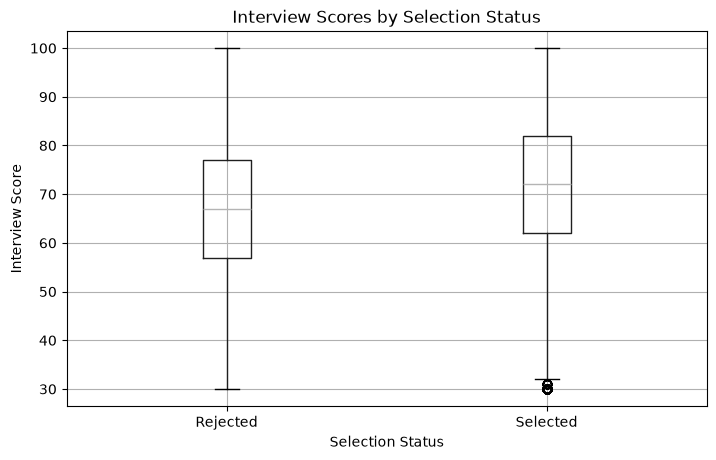

In [54]:
# Compare interview score distributions using a boxplot
print(df_cleaned.groupby('selected')['interview_score'].mean())

df_cleaned.boxplot(column='interview_score', by='selected', figsize=(8, 5))
plt.title('Interview Scores by Selection Status')
plt.suptitle('')
plt.xlabel('Selection Status')
plt.ylabel('Interview Score')
plt.show()

selected           Rejected  Selected
highest_education                    
Bachelor              27431     27376
Diploma                4934      5084
High School            2476      2525
Master                12778     12507
PhD                    2381      2508


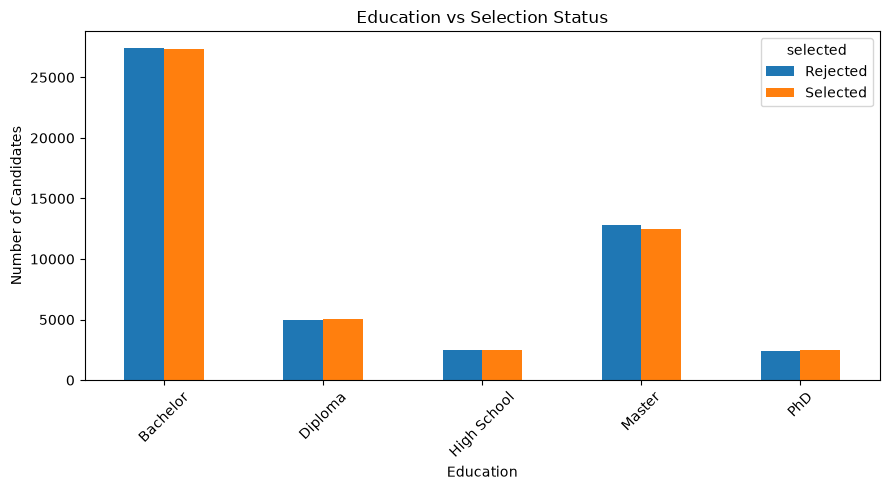

In [55]:
# Compare selected and rejected candidate counts across education categories
education_selection = pd.crosstab(
    df_cleaned['highest_education'],
    df_cleaned['selected']
)

print(education_selection)

education_selection.plot(kind='bar', figsize=(9, 5))
plt.title('Education vs Selection Status')
plt.xlabel('Education')
plt.ylabel('Number of Candidates')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

selected                   Rejected  Selected
job_role                                     
AI Engineer                   49.89     50.11
Backend Developer             49.84     50.16
Business Analyst              48.86     51.14
Cloud Engineer                50.70     49.30
Cyber Security Analyst        49.99     50.01
Data Scientist                50.40     49.60
Database Administrator        50.64     49.36
DevOps Engineer               50.86     49.14
Frontend Developer            49.63     50.37
Full Stack Developer          49.95     50.05
Machine Learning Engineer     49.09     50.91
Mobile App Developer          50.52     49.48
QA Engineer                   49.01     50.99
Software Engineer             49.69     50.31
UI UX Designer                50.93     49.07


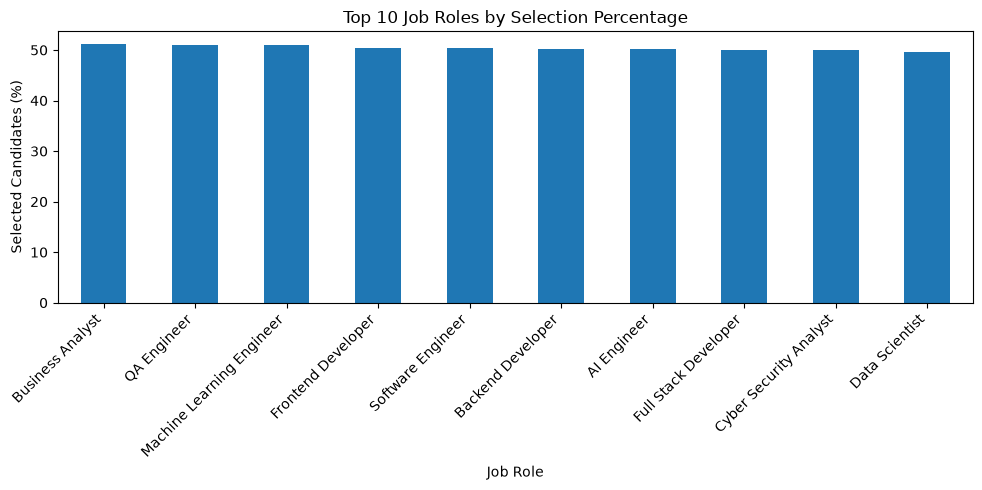

In [56]:
# Calculate selection percentages within each job role
selection_by_role = pd.crosstab(
    df_cleaned['job_role'],
    df_cleaned['selected'],
    normalize='index'
) * 100

print(selection_by_role.round(2))

if 'Selected' in selection_by_role.columns:
    top_roles = selection_by_role['Selected'].sort_values(ascending=False).head(10)

    top_roles.plot(kind='bar', figsize=(10, 5))
    plt.title('Top 10 Job Roles by Selection Percentage')
    plt.xlabel('Job Role')
    plt.ylabel('Selected Candidates (%)')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()
else:
    print("Check selection labels:", df_cleaned['selected'].unique())

          resume_quality_score  ats_score
selected                                 
Rejected              73.76598   49.83446
Selected              75.30126   52.64360


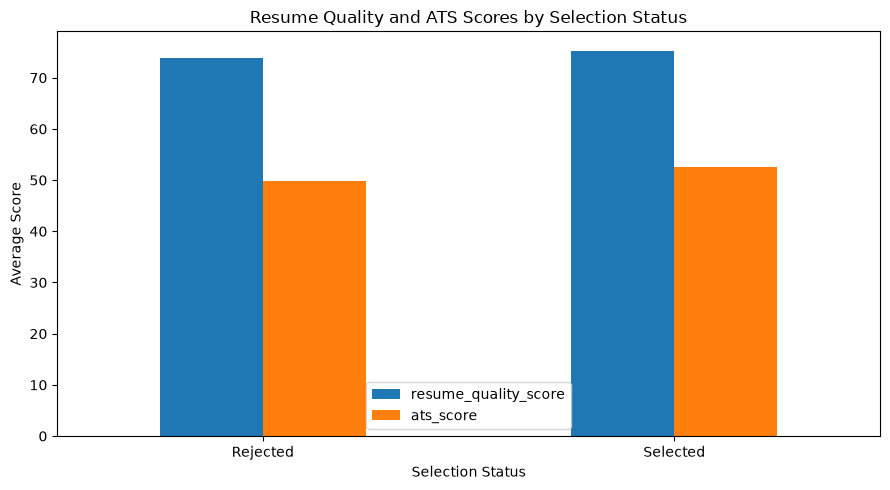

In [57]:
# Compare average resume quality and ATS scores by selection status
resume_scores = df_cleaned.groupby('selected')[
    ['resume_quality_score', 'ats_score']
].mean()

print(resume_scores)

resume_scores.plot(kind='bar', figsize=(9, 5))
plt.title('Resume Quality and ATS Scores by Selection Status')
plt.xlabel('Selection Status')
plt.ylabel('Average Score')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

                           age  cgpa  graduation_year  experience_years  \
age                       1.00  0.00            -0.99              0.99   
cgpa                      0.00  1.00            -0.00              0.00   
graduation_year          -0.99 -0.00             1.00             -1.00   
experience_years          0.99  0.00            -1.00              1.00   
projects_completed       -0.00  0.00             0.00             -0.00   
publications              0.00  0.01            -0.00              0.00   
communication_score      -0.00  0.01             0.00             -0.00   
problem_solving_score     0.00 -0.00            -0.00              0.00   
technical_test_score      0.00  0.00            -0.00              0.00   
interview_score           0.00 -0.00            -0.00              0.00   
aptitude_score           -0.01 -0.00             0.00             -0.00   
expected_salary           0.93  0.00            -0.94              0.94   
resume_quality_score     

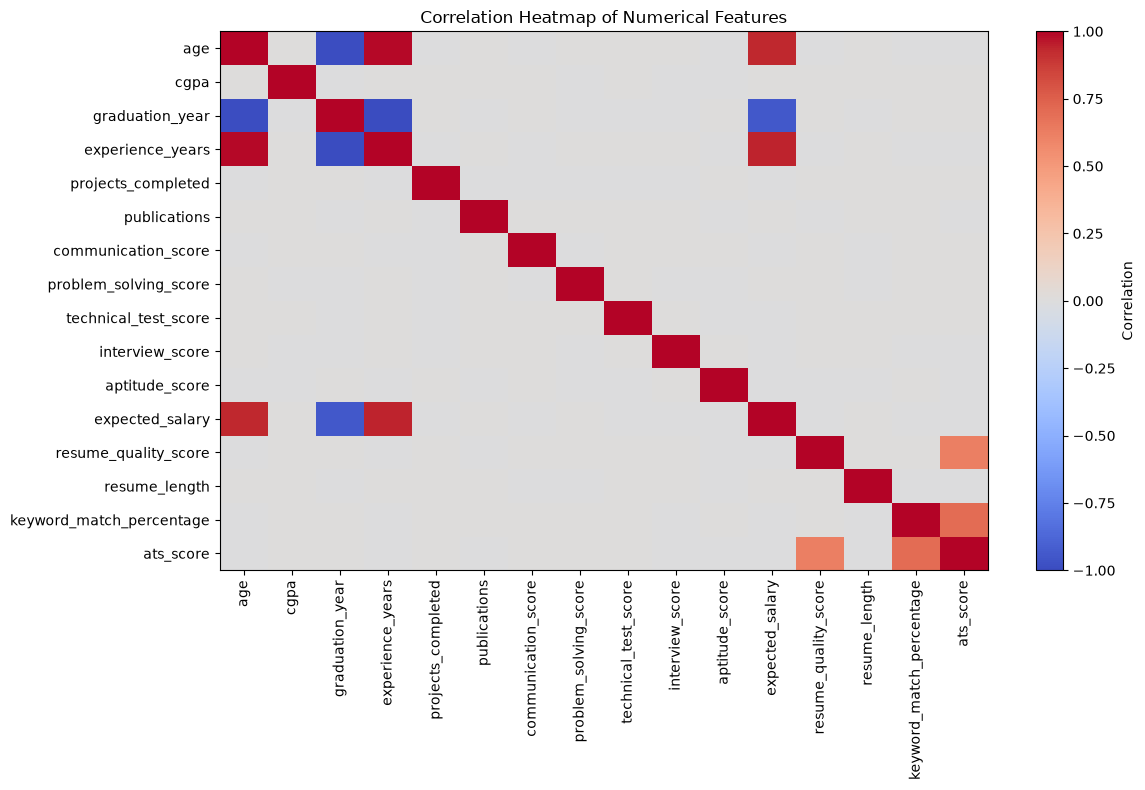

In [58]:
# Calculate and visualize correlations between numerical features
numerical_df = df_cleaned.select_dtypes(include='number')
correlation_matrix = numerical_df.corr()

print(correlation_matrix.round(2))

plt.figure(figsize=(12, 8))
plt.imshow(
    correlation_matrix,
    aspect='auto',
    cmap='coolwarm',
    vmin=-1,
    vmax=1
)
plt.colorbar(label='Correlation')
plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=90
)
plt.yticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns
)
plt.title('Correlation Heatmap of Numerical Features')
plt.tight_layout()
plt.show()

In [59]:
# What variable are we trying to predict?

target = 'selected'

print("Target variable:", target)
print("Target categories:")
print(df_cleaned[target].value_counts())

Target variable: selected
Target categories:
selected
Selected    50000
Rejected    50000
Name: count, dtype: int64


selected
Selected    50000
Rejected    50000
Name: count, dtype: int64
selected
Selected    50.0
Rejected    50.0
Name: proportion, dtype: float64


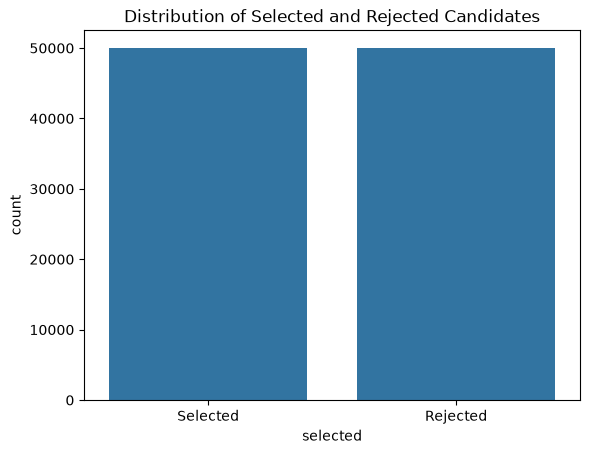

In [60]:
# How many candidates were selected and rejected, and what percentage does each represent?

print(df_cleaned[target].value_counts())
print(df_cleaned[target].value_counts(normalize=True) * 100)

sns.countplot(data=df_cleaned, x=target)
plt.title("Distribution of Selected and Rejected Candidates")
plt.show()

In [61]:
# Which features can be used to predict candidate selection?

excluded_columns = [
    'selected',
    'candidate_id', 'full_name', 'email', 'phone',
    'github_profile', 'linkedin_profile',
    'technical_test_score', 'interview_score'
]

X = df_cleaned.drop(
    columns=excluded_columns,
    errors='ignore'
)

y = df_cleaned[target]

print("Number of input features:", X.shape[1])
print("Number of target records:", y.shape[0])
print("Input features:")
print(X.columns.tolist())

Number of input features: 35
Number of target records: 100000
Input features:
['country', 'city', 'age', 'gender', 'highest_education', 'university', 'field_of_study', 'cgpa', 'graduation_year', 'experience_years', 'previous_companies', 'current_job_title', 'internship_experience', 'leadership_experience', 'technical_skills', 'programming_languages', 'frameworks', 'databases', 'cloud_platform', 'projects_completed', 'certifications', 'publications', 'communication_score', 'problem_solving_score', 'aptitude_score', 'job_role', 'expected_salary', 'preferred_location', 'employment_type', 'remote_preference', 'availability', 'resume_quality_score', 'resume_length', 'keyword_match_percentage', 'ats_score']


In [62]:
# Which input features are numerical and which are categorical?

numerical_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

print("Numerical features:", numerical_features)
print("\nCategorical features:", categorical_features)

Numerical features: ['age', 'cgpa', 'graduation_year', 'experience_years', 'projects_completed', 'publications', 'communication_score', 'problem_solving_score', 'aptitude_score', 'expected_salary', 'resume_quality_score', 'resume_length', 'keyword_match_percentage', 'ats_score']

Categorical features: ['country', 'city', 'gender', 'highest_education', 'university', 'field_of_study', 'previous_companies', 'current_job_title', 'internship_experience', 'leadership_experience', 'technical_skills', 'programming_languages', 'frameworks', 'databases', 'cloud_platform', 'certifications', 'job_role', 'preferred_location', 'employment_type', 'remote_preference', 'availability']


C:\Users\Abijith\AppData\Local\Temp\ipykernel_52452\296673763.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


In [63]:
# How should the dataset be divided into training and testing sets?

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 80000
Testing records: 20000


In [64]:
# How can numerical and categorical features be prepared for the model?

numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(
        handle_unknown='ignore',
        max_categories=100
    ))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numerical_transformer, numerical_features),
    ('cat', categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [65]:
# Can Logistic Regression learn to predict candidate selection?

model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [66]:
# How does the trained model predict selection for unseen candidates?

y_pred = model.predict(X_test)

print("Actual results:")
print(y_test.head(10).tolist())

print("\nPredicted results:")
print(y_pred[:10].tolist())

Actual results:
['Selected', 'Rejected', 'Rejected', 'Selected', 'Rejected', 'Rejected', 'Rejected', 'Rejected', 'Rejected', 'Selected']

Predicted results:
['Selected', 'Rejected', 'Selected', 'Selected', 'Selected', 'Rejected', 'Rejected', 'Selected', 'Rejected', 'Rejected']


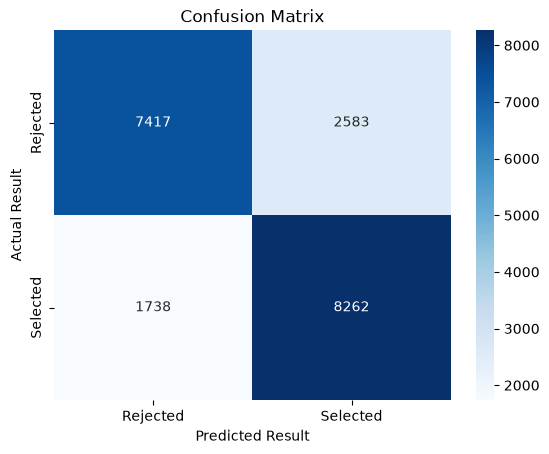

In [67]:
# How many candidates were correctly and incorrectly classified?

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=model.classes_
)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=model.classes_,
    yticklabels=model.classes_
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Result")
plt.ylabel("Actual Result")
plt.show()

In [68]:
# Can the trained model predict the outcome for a new candidate?

new_candidate = X_test.iloc[[0]]

prediction = model.predict(new_candidate)[0]
probabilities = model.predict_proba(new_candidate)[0]

print("Predicted result:", prediction)

for category, probability in zip(
    model.classes_,
    probabilities
):
    print(f"{category}: {probability * 100:.2f}%")

Predicted result: Selected
Rejected: 18.79%
Selected: 81.21%


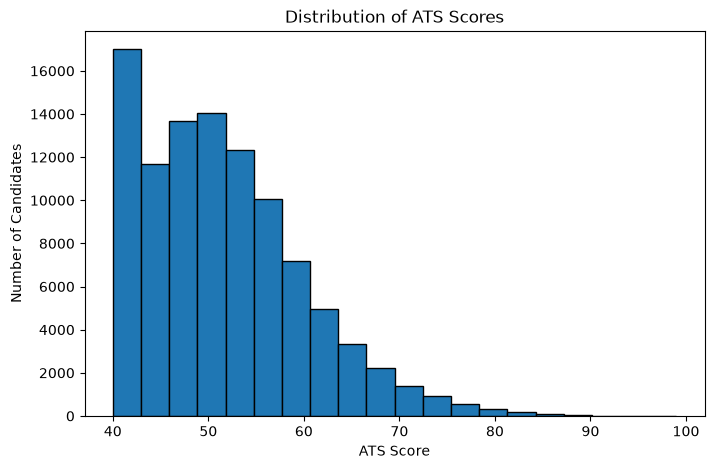

In [69]:
# How are candidates' ATS scores distributed?

plt.figure(figsize=(8, 5))
plt.hist(df_cleaned['ats_score'].dropna(), bins=20, edgecolor='black')
plt.title("Distribution of ATS Scores")
plt.xlabel("ATS Score")
plt.ylabel("Number of Candidates")
plt.show()

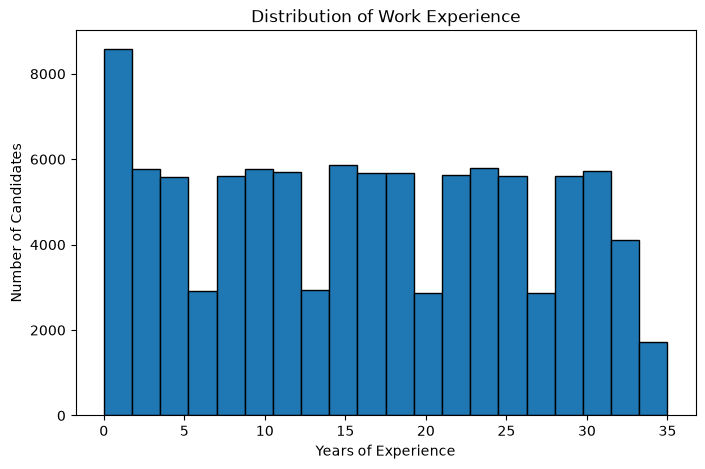

In [70]:
# How are candidates distributed according to their years of experience?

plt.figure(figsize=(8, 5))
plt.hist(df_cleaned['experience_years'].dropna(), bins=20, edgecolor='black')
plt.title("Distribution of Work Experience")
plt.xlabel("Years of Experience")
plt.ylabel("Number of Candidates")
plt.show()

## feature engineering

In [71]:
# How can candidates be grouped into different experience levels?

df_cleaned['experience_level'] = pd.cut(
    df_cleaned['experience_years'],
    bins=[-1, 2, 5, 10, float('inf')],
    labels=['Entry Level', 'Junior', 'Mid Level', 'Senior']
)

print(df_cleaned['experience_level'].value_counts())

experience_level
Senior         65782
Mid Level      14293
Entry Level    11384
Junior          8541
Name: count, dtype: int64


In [72]:
# Can ATS score and resume quality score be combined into one feature?

df_cleaned['combined_resume_score'] = (
    df_cleaned['ats_score'] * 0.5
    + df_cleaned['resume_quality_score'] * 0.5
)

print(df_cleaned[
    ['ats_score', 'resume_quality_score', 'combined_resume_score']
].head())

   ats_score  resume_quality_score  combined_resume_score
0         46                    72                   59.0
1         46                    77                   61.5
2         65                    58                   61.5
3         43                    61                   52.0
4         46                    62                   54.0


##  Exploratory Data Analysis – Conclusion

Exploratory Data Analysis (EDA) was performed on the AI Resume Screening dataset to understand its structure, identify patterns, and examine the relationships between candidate attributes and selection outcomes.

The analysis included statistical summaries, numerical and categorical analysis, histograms, bar charts, box plots, correlation analysis, and comparisons between selected and rejected candidates. Feature engineering was also performed to create additional features, such as experience-level categories and a combined resume score, to explore potentially useful representations of candidate information.

The findings helped identify patterns in candidates' experience, educational background, assessment scores, and resume-related metrics. However, these patterns represent associations within the dataset and do not necessarily establish causal relationships.

Overall, the EDA stage provided a better understanding of the dataset and helped identify relevant features for further analysis. The cleaned and explored dataset can now be reviewed for suitability before proceeding to the next stage of the project: Machine Learning model development.

*Note: The observations from this analysis are specific to the available dataset and should not be interpreted as definitive rules for real-world recruitment decisions.*